In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import time

print("All libraries imported successfully!")

All libraries imported successfully!


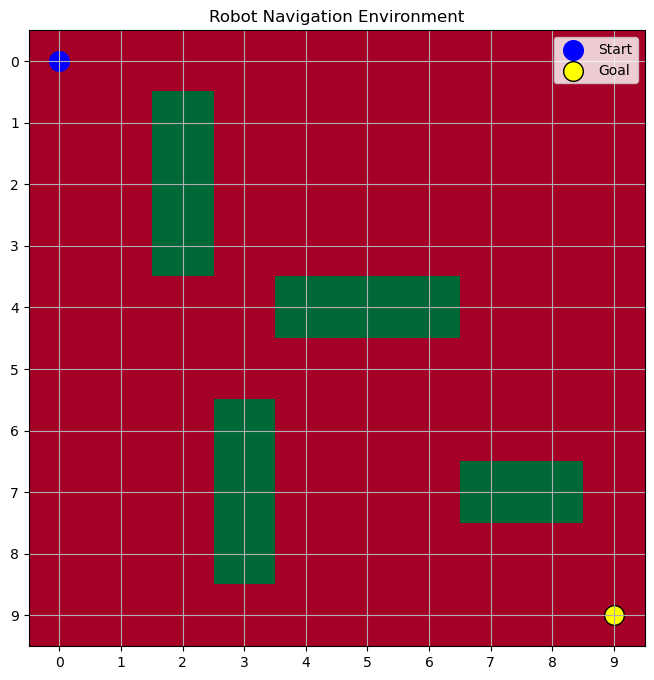

In [2]:
# Grid size
ROWS = 10
COLS = 10

# Starting position and goal
start = (0, 0)
goal = (9, 9)

# Obstacles
obstacles = [
    (1, 2), (2, 2), (3, 2),
    (4, 4), (4, 5), (4, 6),
    (6, 3), (7, 3), (8, 3),
    (7, 7), (7, 8)
]

# Create grid
grid = np.zeros((ROWS, COLS))

# Add obstacles
for obstacle in obstacles:
    grid[obstacle] = -1

# Display grid
plt.figure(figsize=(8, 8))
plt.imshow(grid, cmap="RdYlGn_r")

# Mark start and goal
plt.scatter(start[1], start[0], color="blue", s=200, label="Start")
plt.scatter(goal[1], goal[0], color="yellow", edgecolors="black",
            s=200, label="Goal")

# Add grid lines
plt.xticks(range(COLS))
plt.yticks(range(ROWS))
plt.grid(True)
plt.legend()
plt.title("Robot Navigation Environment")

plt.show()

In [3]:
# Available actions
actions = {
    0: (-1, 0),  # Up
    1: (1, 0),   # Down
    2: (0, -1),  # Left
    3: (0, 1)    # Right
}

print("Available actions:")

for action, movement in actions.items():
    print(f"Action {action}: {movement}")

Available actions:
Action 0: (-1, 0)
Action 1: (1, 0)
Action 2: (0, -1)
Action 3: (0, 1)


In [4]:
def move_robot(state, action):

    # Current position
    row, col = state

    # Action ke according movement
    row_change, col_change = actions[action]

    # New position
    new_row = row + row_change
    new_col = col + col_change

    # Check grid boundaries
    if (new_row < 0 or new_row >= ROWS or
            new_col < 0 or new_col >= COLS):

        return state, -5, False

    # Check obstacle
    if (new_row, new_col) in obstacles:

        return state, -5, False

    # Update robot position
    new_state = (new_row, new_col)

    # Check goal
    if new_state == goal:

        return new_state, 100, True

    # Normal movement reward
    return new_state, -1, False

In [5]:
# Test 1: Move right from start
state = start
action = 3

new_state, reward, done = move_robot(state, action)

print("Current Position:", state)
print("New Position:", new_state)
print("Reward:", reward)
print("Goal Reached:", done)

Current Position: (0, 0)
New Position: (0, 1)
Reward: -1
Goal Reached: False


In [6]:
# Test obstacle collision
state = (0, 2)
action = 1  # Down: (1, 2) is an obstacle

new_state, reward, done = move_robot(state, action)

print("New Position:", new_state)
print("Reward:", reward)
print("Goal Reached:", done)

New Position: (0, 2)
Reward: -5
Goal Reached: False


In [7]:
# Initialize Q-table
Q = np.zeros((ROWS, COLS, len(actions)))

print("Q-Table Shape:", Q.shape)
print("\nInitial Q-Table:")
print(Q)

Q-Table Shape: (10, 10, 4)

Initial Q-Table:
[[[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
 

In [8]:
# Learning parameters
learning_rate = 0.1
discount_factor = 0.95

epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.995

episodes = 2000
max_steps = 200

print("Learning Rate:", learning_rate)
print("Discount Factor:", discount_factor)
print("Initial Epsilon:", epsilon)
print("Total Episodes:", episodes)

Learning Rate: 0.1
Discount Factor: 0.95
Initial Epsilon: 1.0
Total Episodes: 2000


In [9]:
# Store rewards for every episode
episode_rewards = []

# Q-Learning Training
for episode in range(episodes):

    # Reset robot position
    state = start

    total_reward = 0

    for step in range(max_steps):

        row, col = state

        # Epsilon-greedy action selection
        if random.uniform(0, 1) < epsilon:

            # Explore: choose a random action
            action = random.choice(list(actions.keys()))

        else:

            # Exploit: choose the best-known action
            action = np.argmax(Q[row, col])

        # Perform action
        next_state, reward, done = move_robot(state, action)

        next_row, next_col = next_state

        # Current Q-value
        old_value = Q[row, col, action]

        # Maximum future Q-value
        future_value = np.max(Q[next_row, next_col])

        # Q-Learning update
        new_value = old_value + learning_rate * (
            reward + discount_factor * future_value * (not done)
            - old_value
        )

        Q[row, col, action] = new_value

        # Update state and reward
        state = next_state
        total_reward += reward

        # Stop if goal is reached
        if done:
            break

    # Save episode reward
    episode_rewards.append(total_reward)

    # Reduce exploration gradually
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    # Print progress
    if (episode + 1) % 200 == 0:
        print(
            f"Episode: {episode + 1}/{episodes}, "
            f"Reward: {total_reward}, "
            f"Epsilon: {epsilon:.3f}"
        )

print("\nTraining Completed!")

Episode: 200/2000, Reward: 48, Epsilon: 0.367
Episode: 400/2000, Reward: 81, Epsilon: 0.135
Episode: 600/2000, Reward: 83, Epsilon: 0.049
Episode: 800/2000, Reward: 83, Epsilon: 0.018
Episode: 1000/2000, Reward: 83, Epsilon: 0.010
Episode: 1200/2000, Reward: 83, Epsilon: 0.010
Episode: 1400/2000, Reward: 83, Epsilon: 0.010
Episode: 1600/2000, Reward: 83, Epsilon: 0.010
Episode: 1800/2000, Reward: 83, Epsilon: 0.010
Episode: 2000/2000, Reward: 83, Epsilon: 0.010

Training Completed!


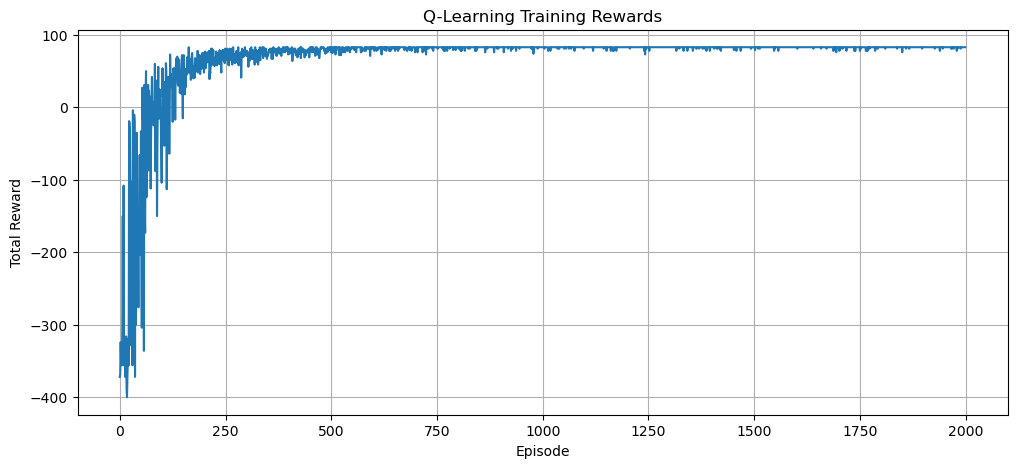

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(episode_rewards)

plt.title("Q-Learning Training Rewards")
plt.xlabel("Episode")
plt.ylabel("Total Reward")

plt.grid(True)
plt.show()

In [11]:
import numpy as np

print("===== PERFORMANCE REPORT =====")
print("Total Episodes:", len(episode_rewards))
print("Average Reward:", round(np.mean(episode_rewards), 2))
print("Best Reward:", np.max(episode_rewards))
print("Worst Reward:", np.min(episode_rewards))
print("Last 100 Episodes Average:",
      round(np.mean(episode_rewards[-100:]), 2))

===== PERFORMANCE REPORT =====
Total Episodes: 2000
Average Reward: 68.33
Best Reward: 83
Worst Reward: -400
Last 100 Episodes Average: 82.76


In [12]:
# Find the best path using the trained Q-table

def find_best_path():

    state = start
    path = [state]
    visited = {state}

    for step in range(ROWS * COLS * 4):

        row, col = state

        # Get actions in descending Q-value order
        sorted_actions = np.argsort(Q[row, col])[::-1]

        moved = False

        # Try the action with the highest Q-value first
        for action in sorted_actions:

            next_state, reward, done = move_robot(state, int(action))

            # Ignore actions that keep the robot in the same position
            if next_state == state:
                continue

            # Avoid loops
            if next_state in visited and not done:
                continue

            state = next_state
            path.append(state)
            visited.add(state)
            moved = True
            break

        if not moved:
            break

        if state == goal:
            break

    return path


# Find the path
best_path = find_best_path()

print("Best Path:")
print(best_path)

print("\nTotal Steps:", len(best_path) - 1)
print("Goal Reached:", best_path[-1] == goal)

Best Path:
[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (1, 5), (1, 6), (1, 7), (2, 7), (2, 8), (3, 8), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9)]

Total Steps: 18
Goal Reached: True


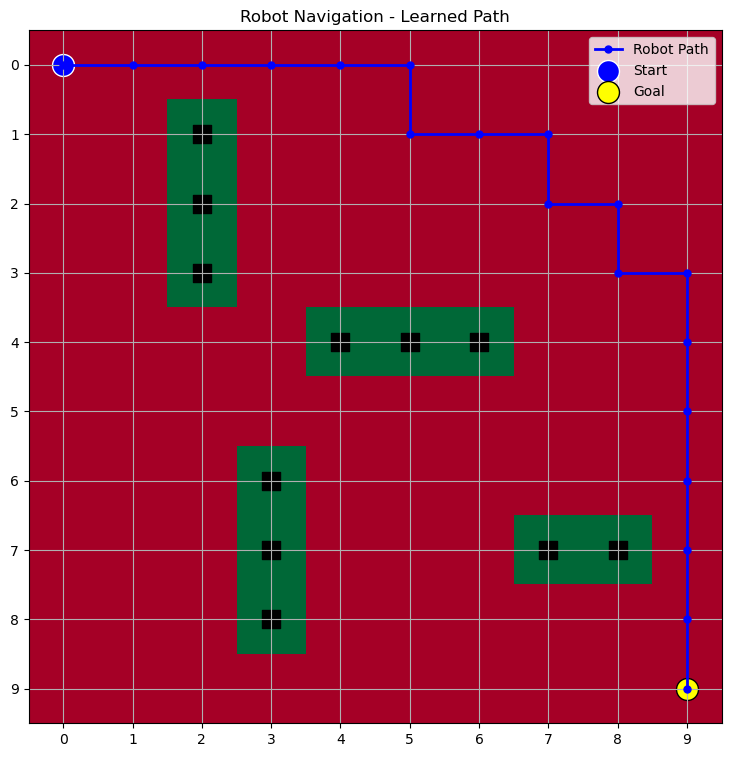

In [13]:
# Visualize the learned path

plt.figure(figsize=(9, 9))

# Draw the environment
plt.imshow(grid, cmap="RdYlGn_r", origin="upper")

# Mark obstacles
for obstacle in obstacles:
    row, col = obstacle
    plt.scatter(col, row, color="black", s=180, marker="s")

# Extract path coordinates
path_rows = [position[0] for position in best_path]
path_cols = [position[1] for position in best_path]

# Draw robot path
plt.plot(path_cols, path_rows, "b-o", linewidth=2, markersize=5,
         label="Robot Path")

# Mark start and goal
plt.scatter(start[1], start[0], color="blue", s=250,
            edgecolors="white", label="Start")

plt.scatter(goal[1], goal[0], color="yellow", s=250,
            edgecolors="black", label="Goal")

plt.xticks(range(COLS))
plt.yticks(range(ROWS))
plt.grid(True)
plt.legend()
plt.title("Robot Navigation - Learned Path")
plt.show()

In [14]:
# Calculate average reward

last_100_rewards = episode_rewards[-100:]

average_reward = np.mean(last_100_rewards)

print("Average Reward in Last 100 Episodes:", round(average_reward, 2))
print("Best Reward:", max(episode_rewards))
print("Final Epsilon:", round(epsilon, 4))

Average Reward in Last 100 Episodes: 82.76
Best Reward: 83
Final Epsilon: 0.01


In [15]:
import numpy as np

np.save("q_table.npy", Q)

print("Q-Table saved successfully!")

Q-Table saved successfully!


In [16]:
import os

print("Notebook folder:", os.getcwd())
print("Q-table exists:", os.path.exists("q_table.npy"))

Notebook folder: C:\Users\AKSHUU7001\Robot-Navigation-RL
Q-table exists: True


In [17]:
import numpy as np
import os

np.save("q_table.npy", Q)

print("Q-table saved successfully!")
print("File location:", os.path.abspath("q_table.npy"))


Q-table saved successfully!
File location: C:\Users\AKSHUU7001\Robot-Navigation-RL\q_table.npy


In [18]:

# Evaluate the trained Q-learning agent

test_episodes = 100
successful_episodes = 0
test_rewards = []

for episode in range(test_episodes):
    state = start
    total_reward = 0

    for step in range(max_steps):
        row, col = state

        # Select the best action from the trained Q-table
        action = np.argmax(Q[row, col])

        next_state, reward, done = move_robot(state, action)

        total_reward += reward
        state = next_state

        if done:
            successful_episodes += 1
            break

        # Stop if the robot repeatedly hits a boundary
        # or obstacle and cannot move.
        # The environment returns the same state for invalid moves.

    test_rewards.append(total_reward)

success_rate = (successful_episodes / test_episodes) * 100

print("===== AGENT EVALUATION REPORT =====")
print("Test Episodes:", test_episodes)
print("Successful Episodes:", successful_episodes)
print("Failed Episodes:", test_episodes - successful_episodes)
print("Goal Success Rate:", round(success_rate, 2), "%")
print("Average Test Reward:", round(np.mean(test_rewards), 2))



===== AGENT EVALUATION REPORT =====
Test Episodes: 100
Successful Episodes: 100
Failed Episodes: 0
Goal Success Rate: 100.0 %
Average Test Reward: 83.0


In [21]:

# Robot Path Performance Report

path = find_best_path()

goal_reached = (path[-1] == goal)

if goal_reached:
    path_length = len(path) - 1

    print("===== ROBOT PATH REPORT =====")
    print("Start Position:", start)
    print("Goal Position:", goal)
    print("Goal Reached:", goal_reached)
    print("Total Positions:", len(path))
    print("Total Steps:", path_length)
    print("Path:", path)

else:
    print("Robot could not reach the goal.")





===== ROBOT PATH REPORT =====
Start Position: (0, 0)
Goal Position: (9, 9)
Goal Reached: True
Total Positions: 19
Total Steps: 18
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (1, 5), (1, 6), (1, 7), (2, 7), (2, 8), (3, 8), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9)]
